Import libraries


In [2]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]=(10,6)
plt.rcParams["savefig.dpi"]=300

OUTPUT_DIR=Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("All libraries are installed successfully")

All libraries are installed successfully


Load sales dataset


In [3]:
# Reload the original dataset to restore the text columns
DATA_PATH = Path("../data/sales.csv")
df = pd.read_csv(DATA_PATH)

print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment', 'Sales', 'Profit', 'Quantity']


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,11/8/2016,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,6/12/2016,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,10/11/2015,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,10/11/2015,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2


In [4]:
# Clean the dataset

df = df.drop_duplicates().copy()
df.columns = df.columns.str.strip()

# Convert numerical columns
for col in ["Sales", "Profit", "Quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse dates automatically
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

print("Rows remaining:", len(df))
print("Missing dates:", df["Order Date"].isna().sum())
print("Missing values:")
print(df.isnull().sum())

display(df.head())

Rows remaining: 9992
Missing dates: 0
Missing values:
Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,2016-11-08,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,2016-11-08,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,2016-06-12,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,2015-10-11,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,2015-10-11,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2


calculate the key business metrics

In [5]:

total_revenue=df["Sales"].sum()

total_profit=df["Profit"].sum()

total_units=df["Quantity"].sum()
profit_margin=((total_profit/total_revenue)*100
               if total_revenue!=0 else 0
)
average_sales_per_second=df["Sales"].mean()

print("=" * 40)
print("          SALES SUMMARY")
print("=" * 40)
print(f"Total revenue      :{total_revenue:,.2f}")
print(f"Total profit       :{total_profit:.2f}")
print(f"Total unit soled   :{total_units:.0f}")
print(f"profit margin      :{profit_margin:.2f}% ")
print(f"Average sales/Record :{average_sales_per_second:,.2f} ")


          SALES SUMMARY
Total revenue      :2,296,914.56
Total profit       :286408.34
Total unit soled   :37869
profit margin      :12.47% 
Average sales/Record :229.88 


Analyse monthly sales trends

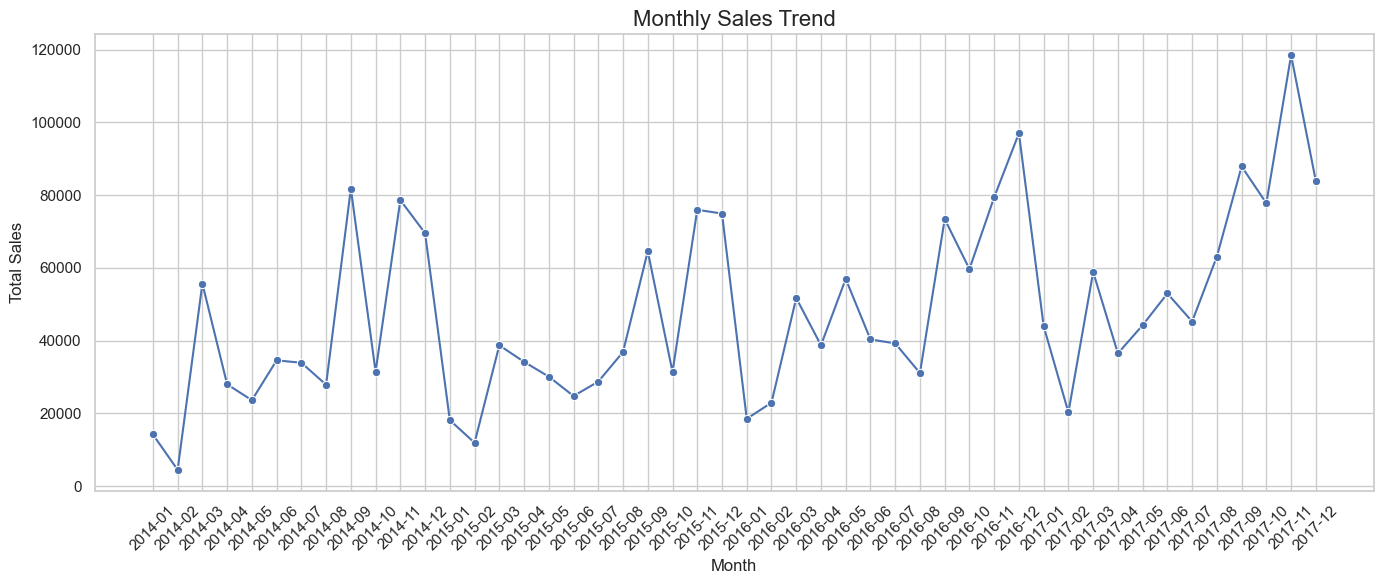

In [31]:
df["YearMonth"]=df["Order Date"].dt.to_period("M")
monthly_sales=(
    df.groupby("YearMonth")["Sales"]
    .sum()
    .reset_index()
)
monthly_sales["YearMonth"]=monthly_sales["YearMonth"].astype(str)
plt.figure(figsize=(14,6))
sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Sales",
    marker="o"

)
plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Analyze sales by product category

In [7]:

# Sales and profit by category

category_sales = (
    df.groupby("Category")[["Sales", "Profit", "Quantity"]]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
)

display(category_sales)



,Category,Sales,Profit,Quantity
2,Technology,836154.0330,145454.9481,6939
0,Furniture,741713.4953,18462.5924,8024
1,Office Supplies,719047.0320,122490.8008,22906


category sales chart

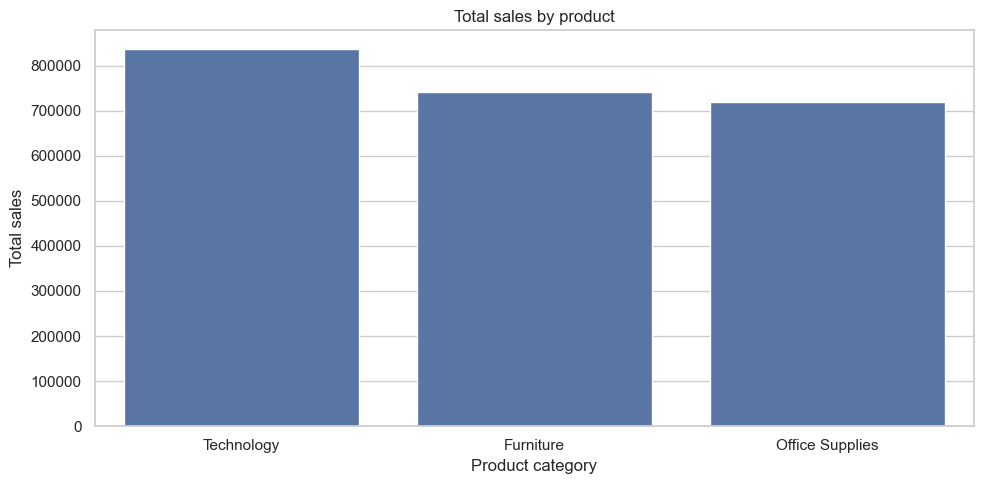

In [8]:
plt.figure(figsize=(10,5))
sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales"
)
plt.title("Total sales by product")
plt.xlabel("Product category")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()


Analyze profit by category

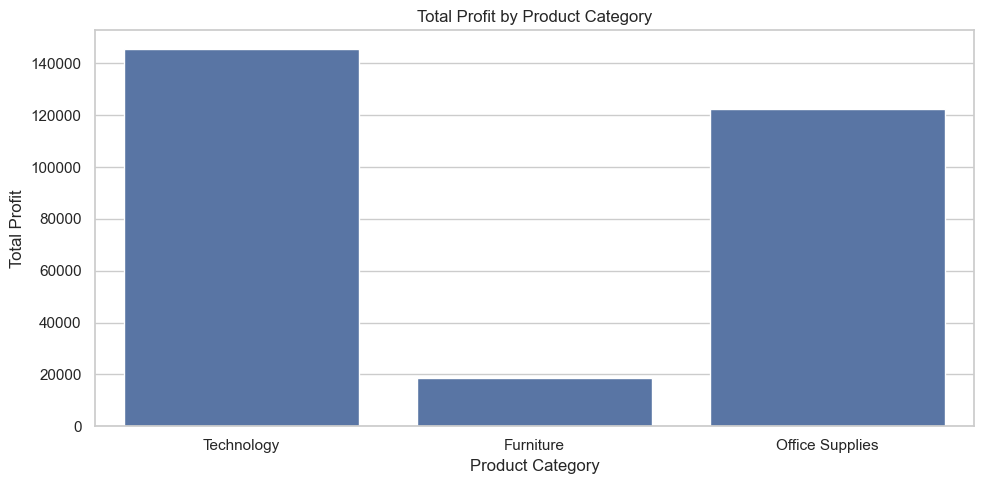

In [9]:

# Visualize profit by category

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Profit"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()


Sales and profit by region

In [10]:

# Sales and profit by category

region_analysis = (
    df.groupby("Region")[["Sales", "Profit", "Quantity"]]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
)

display(region_analysis )


,Region,Sales,Profit,Quantity
3,West,725457.8245,108418.4489,12266
1,East,678499.8680,91534.8388,10616
0,Central,501239.8908,39706.3625,8780
2,South,391716.9770,46748.6911,6207


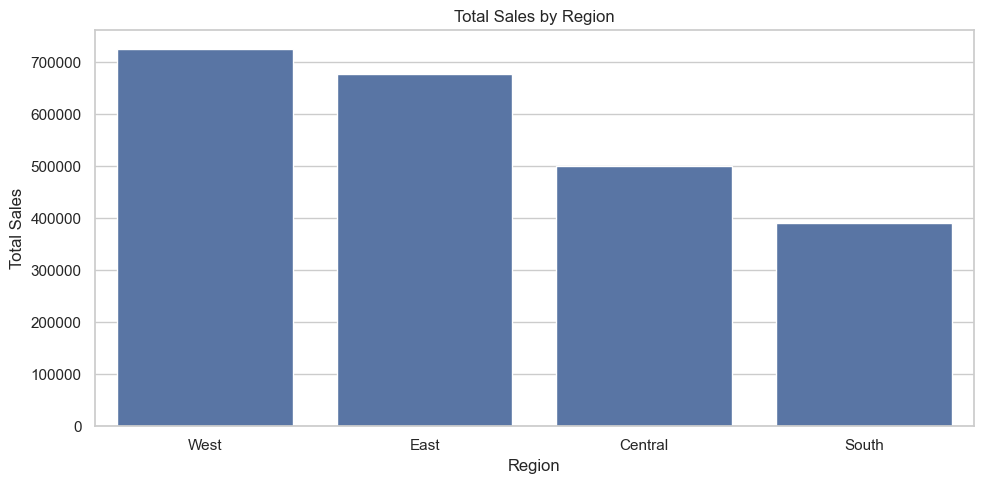

In [11]:

# Sales by region chart

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


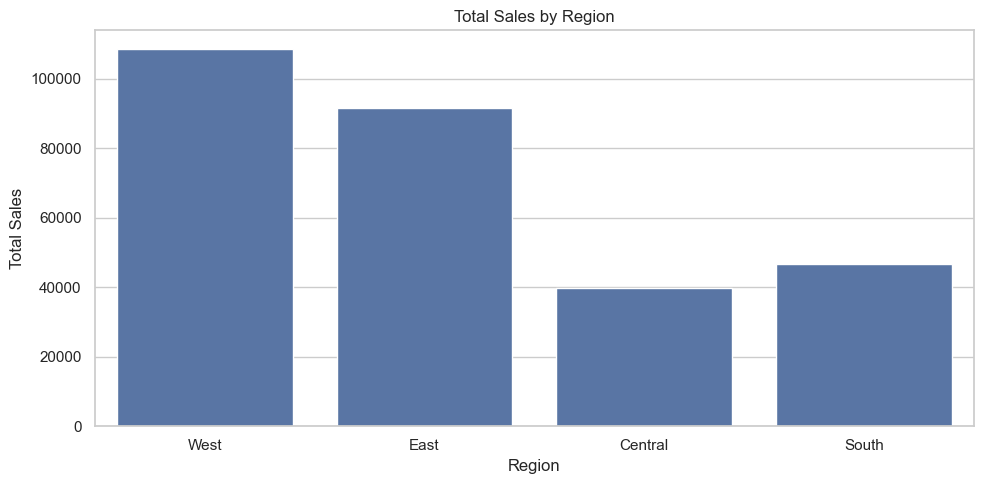

In [12]:

# Sales by region chart

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Profit"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


Sales and profit by customer segment

In [13]:

segment_analysis = (
    df.groupby("Segment")[["Sales", "Profit", "Quantity"]]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
)

display(segment_analysis)


,Segment,Sales,Profit,Quantity
0,Consumer,1.161401e+06,134119.2092,19521
1,Corporate,7.061414e+05,91978.3948,11606
2,Home Office,4.293718e+05,60310.7373,6742


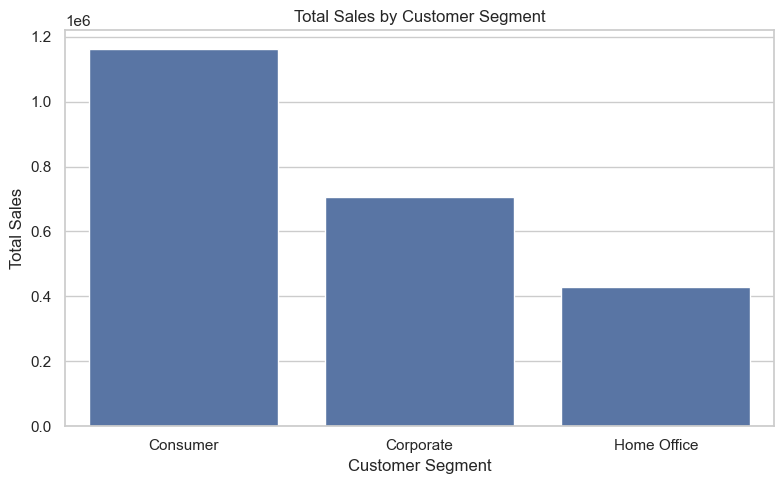

In [14]:

# Visualize sales by customer segment

plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Sales"
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


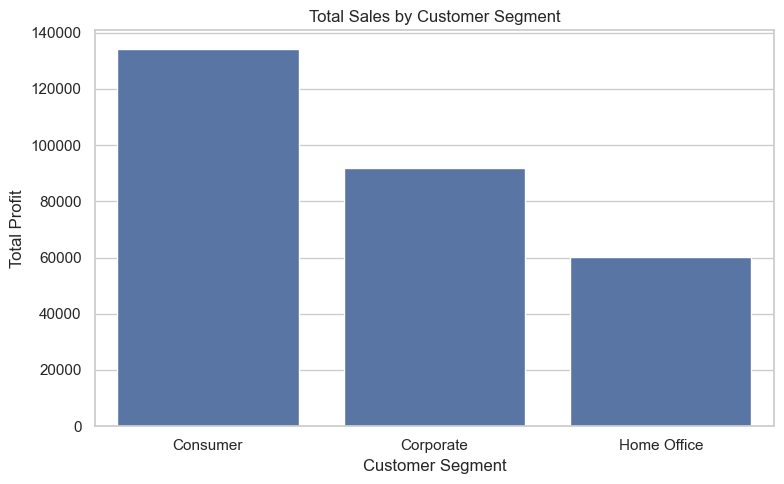

In [15]:

# Visualize profit by customer segment

plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Profit"
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit" )
plt.tight_layout()
plt.show()

Find the top 10 states

In [16]:

state_sales = (
    df.groupby("State")[["Sales", "Profit"]]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
    .head(10)
)

display(state_sales)

,State,Sales,Profit
3,California,457687.6315,76381.3871
30,New York,310876.2710,74038.5486
41,Texas,170188.0458,-25729.3563
45,Washington,138641.2700,33402.6517
36,Pennsylvania,116511.9140,-15559.9603
8,Florida,89473.7080,-3399.3017
11,Illinois,80166.1010,-12607.8870
33,Ohio,77976.7640,-16959.3178
20,Michigan,76269.6140,24463.1876
44,Virginia,70636.7200,18597.9504


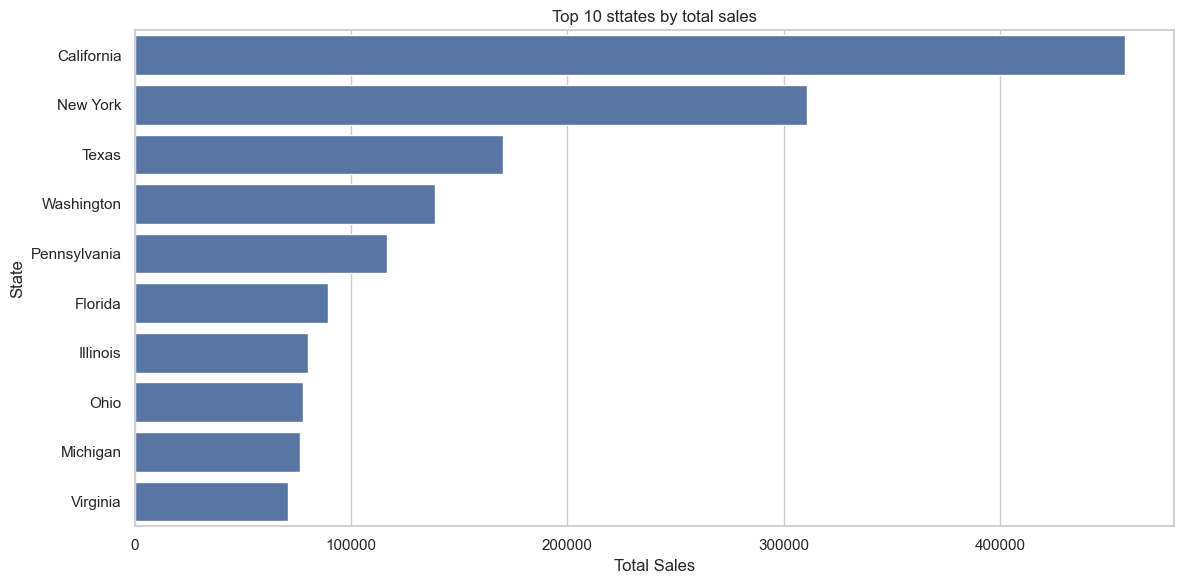

In [17]:
plt.figure(figsize=(12,6))
sns.barplot(
    data=state_sales,
    x="Sales",
    y="State"

)
plt.title('Top 10 sttates by total sales')
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.show()

Analyze sub-categories

In [18]:
subcategory_analysis = (
    df.groupby("Sub-Category")[["Sales", "Profit","Quantity"]]
    .sum()
    .reset_index()
    .sort_values(by="Sales", ascending=False)
   
)

display(subcategory_analysis)

,Sub-Category,Sales,Profit,Quantity
13,Phones,330007.0540,44515.7306,3289
5,Chairs,328167.7310,26602.2251,2354
14,Storage,223843.6080,21278.8264,3158
16,Tables,206965.5320,-17725.4811,1241
3,Binders,203412.7330,30221.7633,5974
11,Machines,189238.6310,3384.7569,440
0,Accessories,167380.3180,41936.6357,2976
6,Copiers,149528.0300,55617.8249,234
4,Bookcases,114879.9963,-3472.5560,868
1,Appliances,107532.1610,18138.0054,1729


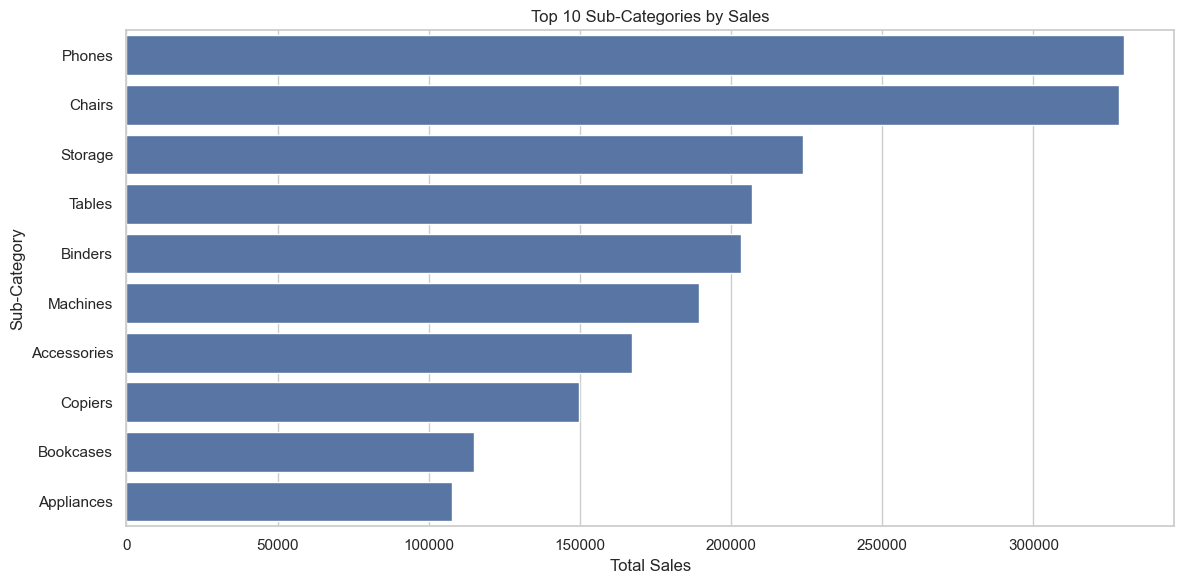

In [19]:

# Top 10 sub-categories by sales

top_subcategories = subcategory_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_subcategories,
    x="Sales",
    y="Sub-Category"
)

plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()


Find the most and least profitable sub-categories

In [20]:

profit_analysis= (
    df.groupby("Sub-Category")[["Sales", "Profit","Quantity"]]
    .sum()
    .reset_index()
    .sort_values(by="Profit", ascending=False)
   
)
print("Top 5 profitable sub-categories")
display(profit_analysis.head(5))
print("Top 5 least profitable sub-categories")
display(profit_analysis.tail(5))  

Top 5 profitable sub-categories


,Sub-Category,Sales,Profit,Quantity
6,Copiers,149528.030,55617.8249,234
13,Phones,330007.054,44515.7306,3289
0,Accessories,167380.318,41936.6357,2976
12,Paper,78479.206,34053.5693,5178
3,Binders,203412.733,30221.7633,5974


Top 5 least profitable sub-categories


,Sub-Category,Sales,Profit,Quantity
11,Machines,189238.6310,3384.7569,440
8,Fasteners,3024.2800,949.5182,914
15,Supplies,46673.5380,-1189.0995,647
4,Bookcases,114879.9963,-3472.5560,868
16,Tables,206965.5320,-17725.4811,1241


Visualize profit by sub-category

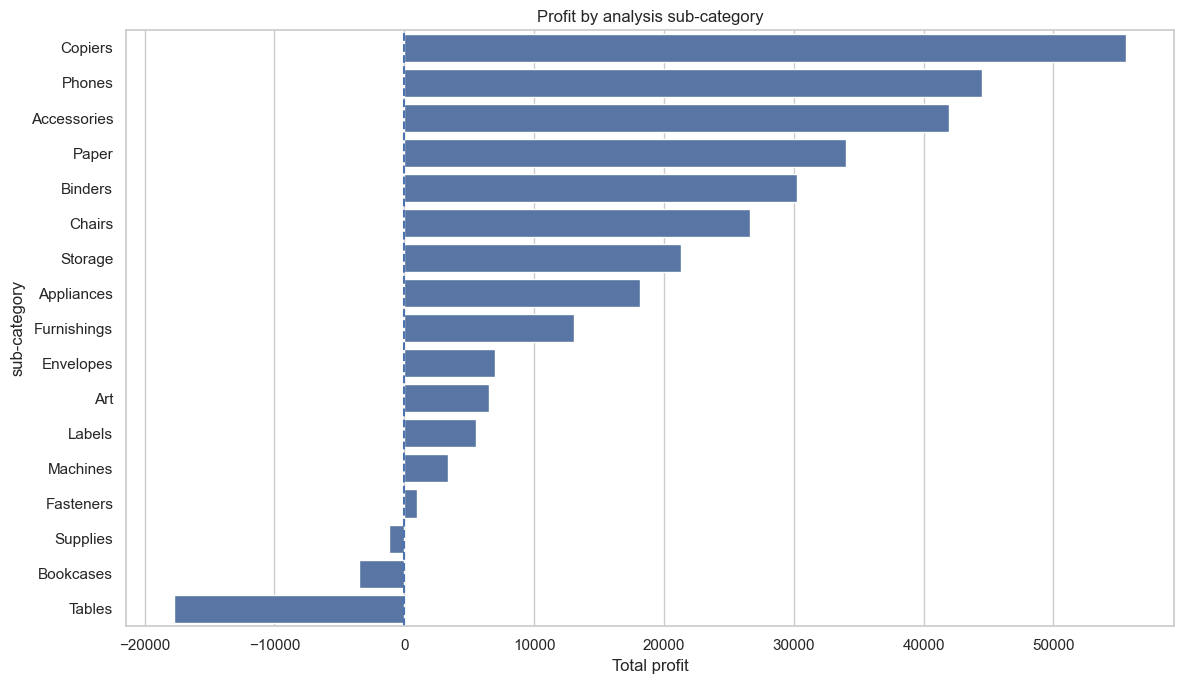

In [21]:
plt.figure(figsize=(12,7))
sns.barplot(
    data=profit_analysis,
    x="Profit",
    y="Sub-Category"
)
plt.title("Profit by analysis sub-category")
plt.xlabel("Total profit")
plt.ylabel("sub-category")
plt.axvline(x=0,linestyle="--")
plt.tight_layout()
plt.show()

Analyze quarterly sales

,Quarter,Sales
0,2014Q1,74447.7960
1,2014Q2,86257.3876
2,2014Q3,143633.2123
3,2014Q4,179627.7302
4,2015Q1,68851.7386
5,2015Q2,89124.1870
6,2015Q3,130254.6472
7,2015Q4,182297.0082
8,2016Q1,93237.1810
9,2016Q2,136082.3010


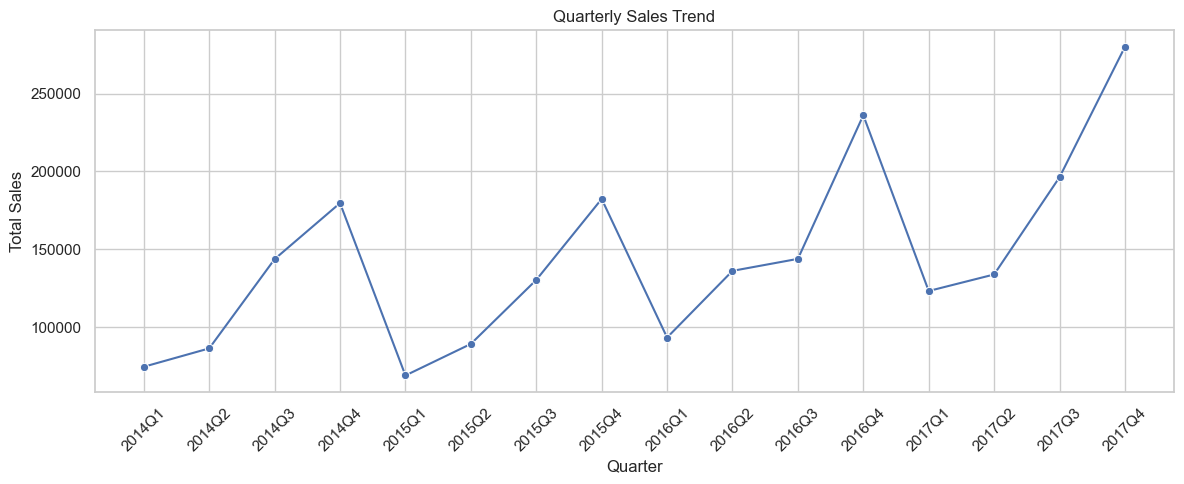

In [22]:

# Quarterly sales analysis

df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)

quarterly_sales = (
    df.groupby("Quarter")["Sales"]
    .sum()
    .reset_index()
)

display(quarterly_sales)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=quarterly_sales,
    x="Quarter",
    y="Sales",
    marker="o"
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [23]:

# Generate key business insights

best_category = category_sales.loc[
    category_sales["Sales"].idxmax()
]

best_region = region_analysis.loc[
    region_analysis["Sales"].idxmax()
]

best_segment = segment_analysis.loc[
    segment_analysis["Sales"].idxmax()
]

best_state = state_sales.loc[
    state_sales["Sales"].idxmax()
]

best_profit_subcategory = profit_analysis.loc[
    profit_analysis["Profit"].idxmax()
]

worst_profit_subcategory = profit_analysis.loc[
    profit_analysis["Profit"].idxmin()
]

print("========== KEY BUSINESS INSIGHTS ==========")

print(
    f"Highest Sales Category: {best_category['Category']} "
    f"(Sales: {best_category['Sales']:,.2f})"
)

print(
    f"Highest Sales Region: {best_region['Region']} "
    f"(Sales: {best_region['Sales']:,.2f})"
)

print(
    f"Highest Sales Customer Segment: {best_segment['Segment']} "
    f"(Sales: {best_segment['Sales']:,.2f})"
)

print(
    f"Top State in the Top-10 List: {best_state['State']} "
    f"(Sales: {best_state['Sales']:,.2f})"
)

print(
    f"Most Profitable Sub-Category: "
    f"{best_profit_subcategory['Sub-Category']} "
    f"(Profit: {best_profit_subcategory['Profit']:,.2f})"
)

print(
    f"Least Profitable Sub-Category: "
    f"{worst_profit_subcategory['Sub-Category']} "
    f"(Profit: {worst_profit_subcategory['Profit']:,.2f})"
)



========== KEY BUSINESS INSIGHTS ==========
Highest Sales Category: Technology (Sales: 836,154.03)
Highest Sales Region: West (Sales: 725,457.82)
Highest Sales Customer Segment: Consumer (Sales: 1,161,401.34)
Top State in the Top-10 List: California (Sales: 457,687.63)
Most Profitable Sub-Category: Copiers (Profit: 55,617.82)
Least Profitable Sub-Category: Tables (Profit: -17,725.48)


In [24]:

# Business recommendations

print("========== BUSINESS RECOMMENDATIONS ==========")

print(
    f"1. Focus on the {best_category['Category']} category "
    "and investigate opportunities to grow its sales."
)

print(
    f"2. Study successful sales strategies in the "
    f"{best_region['Region']} region."
)

print(
    f"3. Develop targeted offers for the "
    f"{best_segment['Segment']} customer segment."
)

print(
    f"4. Investigate the reasons behind low profitability in "
    f"{worst_profit_subcategory['Sub-Category']}."
)

print(
    f"5. Learn from the pricing, costs, and product mix of "
    f"{best_profit_subcategory['Sub-Category']}, "
    "the most profitable sub-category."
)

print(
    "6. Monitor monthly and quarterly trends to improve "
    "sales forecasting and inventory planning."
)


========== BUSINESS RECOMMENDATIONS ==========
1. Focus on the Technology category and investigate opportunities to grow its sales.
2. Study successful sales strategies in the West region.
3. Develop targeted offers for the Consumer customer segment.
4. Investigate the reasons behind low profitability in Tables.
5. Learn from the pricing, costs, and product mix of Copiers, the most profitable sub-category.
6. Monitor monthly and quarterly trends to improve sales forecasting and inventory planning.


In [25]:

# Create an output folder and save analysis results

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

category_sales.to_csv(
    output_dir / "category_analysis.csv",
    index=False
)

region_analysis.to_csv(
    output_dir / "region_analysis.csv",
    index=False
)

segment_analysis.to_csv(
    output_dir / "segment_analysis.csv",
    index=False
)

state_sales.to_csv(
    output_dir / "top_10_states.csv",
    index=False
)

profit_analysis.to_csv(
    output_dir / "subcategory_profit_analysis.csv",
    index=False
)

monthly_sales.to_csv(
    output_dir / "monthly_sales.csv",
    index=False
)

quarterly_sales.to_csv(
    output_dir / "quarterly_sales.csv",
    index=False
)

print("Analysis results saved successfully in the outputs folder.")


Analysis results saved successfully in the outputs folder.


analyse the seasonal sales patterns

In [26]:
df["Month"]=df["Order Date"].dt.month
df["MonthName"]=df["Order Date"].dt.month_name()
seasonal_sales=(
    df.groupby(["Month","MonthName"])["Sales"]
    .sum()
    .reset_index()
    .sort_values("Month")
)
display(seasonal_sales)

,Month,MonthName,Sales
0,1,January,94924.8356
1,2,February,59751.2514
2,3,March,205005.4888
3,4,April,137480.7566
4,5,May,155028.8117
5,6,June,152718.6793
6,7,July,147233.1690
7,8,August,159044.0630
8,9,September,307649.9457
9,10,October,200322.9847


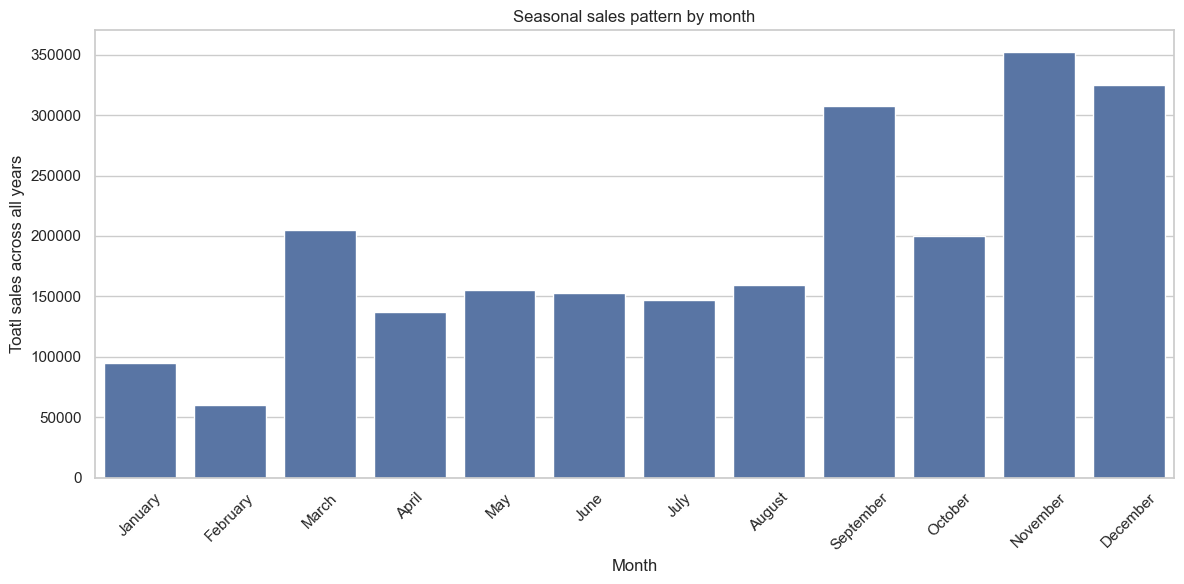

In [27]:
# Visualize profit by category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_sales,
    x="MonthName",
    y="Sales"
)

plt.title("Seasonal sales pattern by month")
plt.xlabel("Month")
plt.ylabel("Toatl sales across all years")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Seasonal_sales.png",dpi=300,bbox_inches="tight")
plt.show()

export the seasonal results

In [38]:

# Create a folder to store high-resolution charts

charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)

print("Charts folder created:", charts_dir.resolve())


Charts folder created: C:\Users\Akshaya\Downloads\CodeNova_Task1_Sales_Analysis\CodeNova_Task1_Sales_Analysis\notebooks\charts


to save the charts

In [35]:
from pathlib import Path
charts_dir=Path("Outputs")
charts_dir.mkdir(parents=True,exist_ok=True)

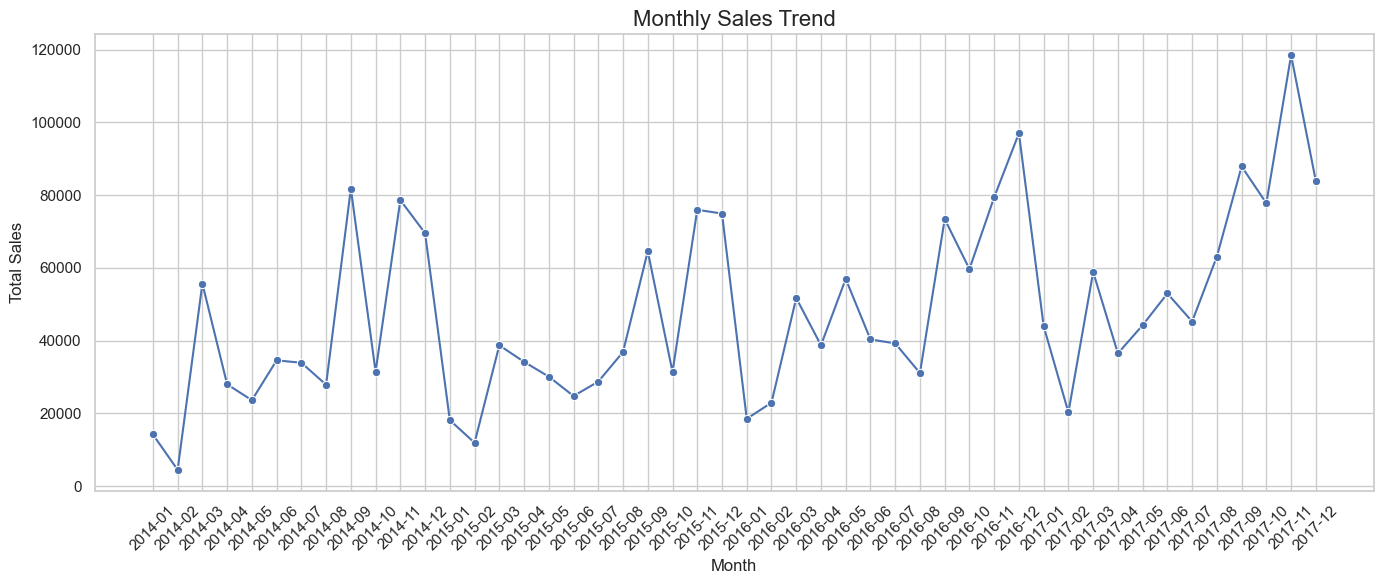

In [40]:


# Monthly sales chart - high-resolution export

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_dir / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()




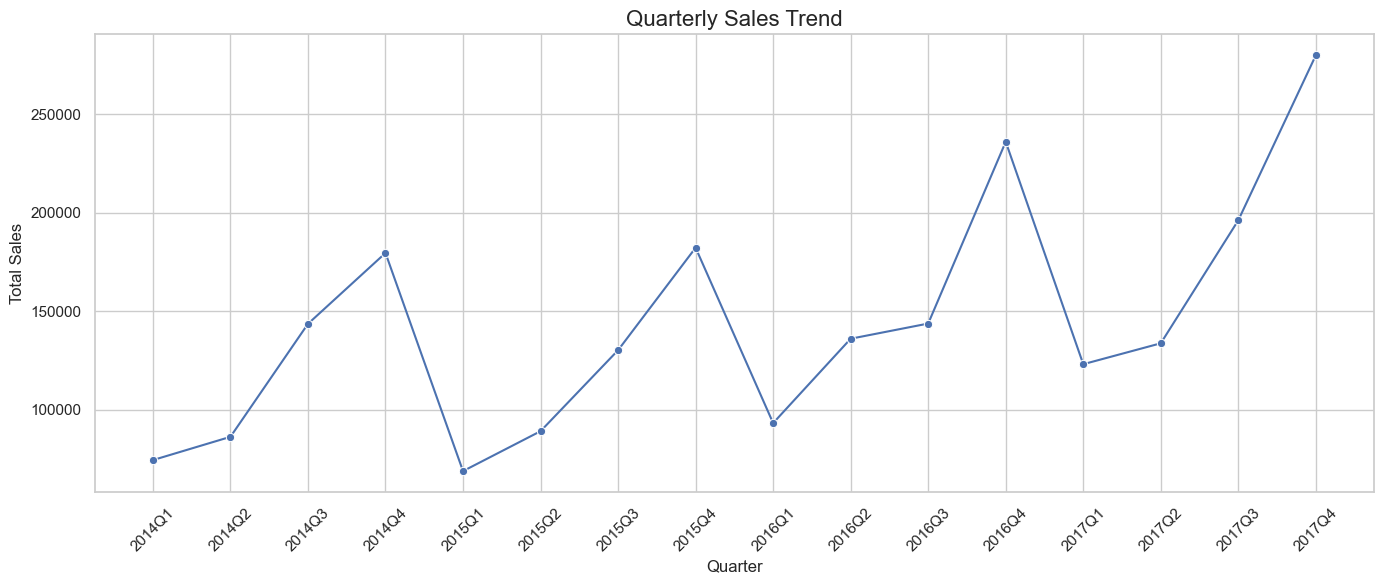

In [41]:
# 2. Quarterly sales trend
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=quarterly_sales,
    x="Quarter",
    y="Sales",
    marker="o"
)
plt.title("Quarterly Sales Trend", fontsize=16)
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(charts_dir / "quarterly_sales_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


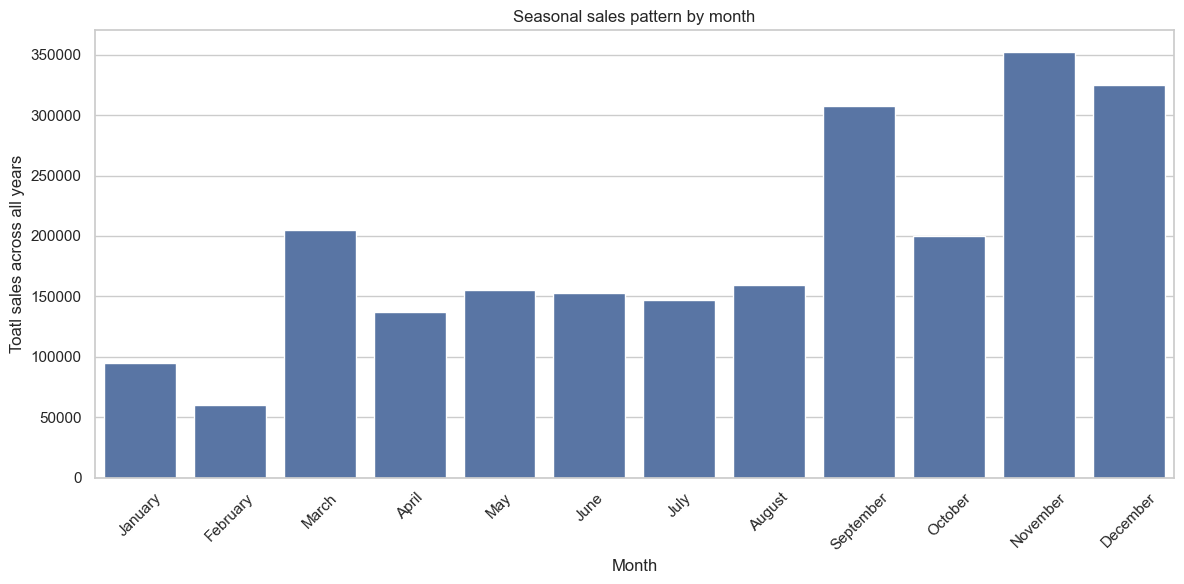

In [42]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_sales,
    x="MonthName",
    y="Sales"
)

plt.title("Seasonal sales pattern by month")
plt.xlabel("Month")
plt.ylabel("Toatl sales across all years")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Seasonal_sales.png",dpi=300,bbox_inches="tight")
plt.show()
plt.close()

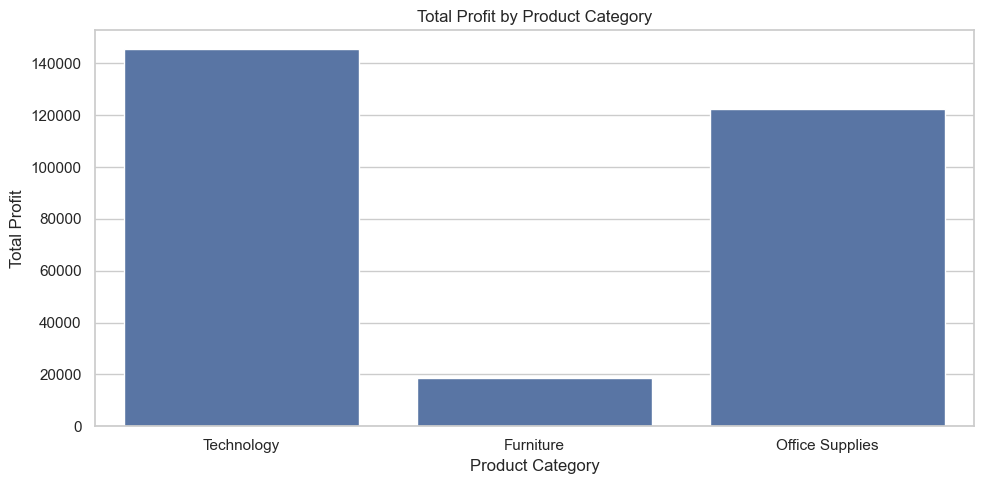

In [43]:
# 5. Profit by category


plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Profit"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()

plt.savefig(charts_dir / "category_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()

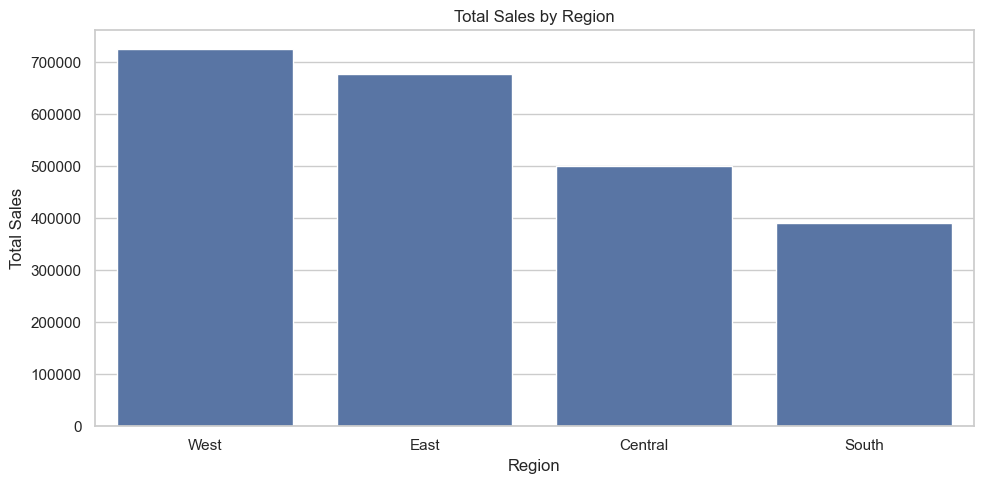

In [44]:
# 5. Profit by category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig(charts_dir / "regional_sales.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

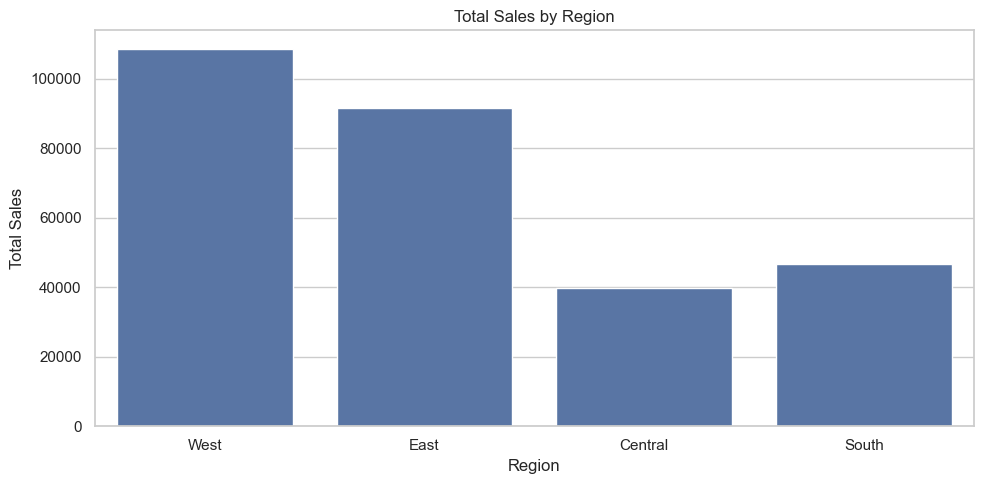

In [45]:
# 7. Profit by region
plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Profit"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig(charts_dir / "regional_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

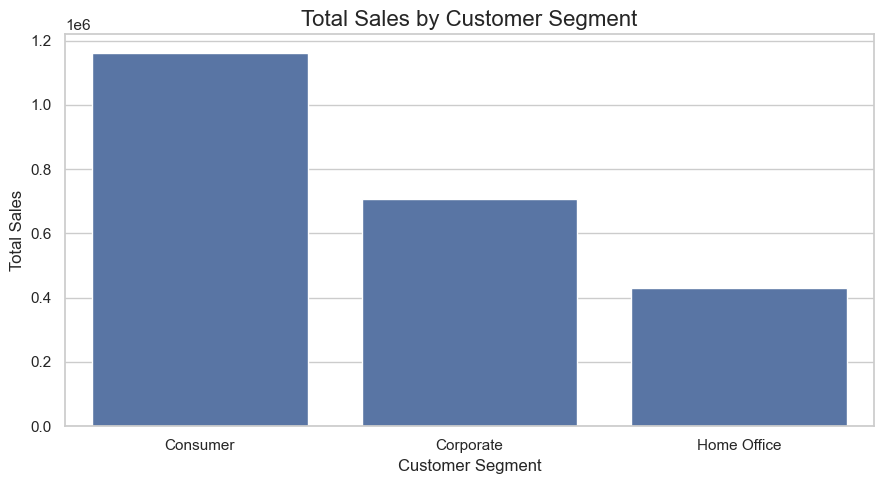

In [46]:
# 8. Sales by customer segment
plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Sales"
)
plt.title("Total Sales by Customer Segment", fontsize=16)
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig(charts_dir / "segment_sales.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


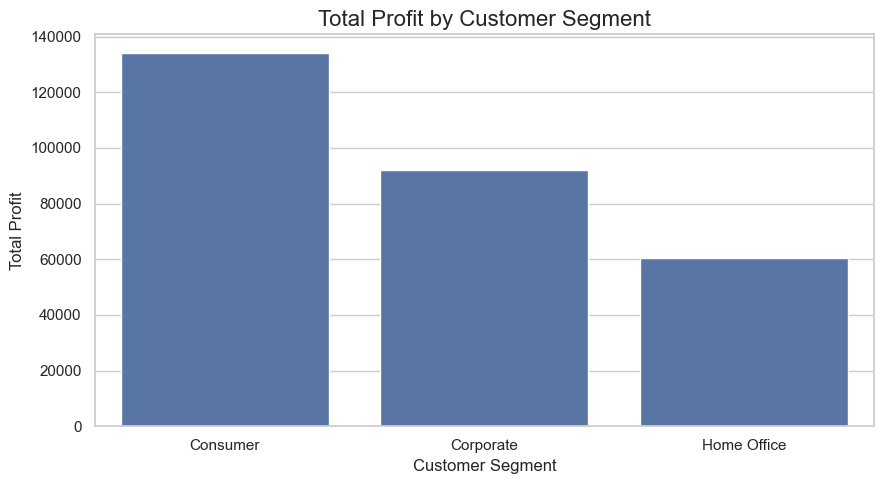

In [47]:

# 9. Profit by customer segment
plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Profit"
)
plt.title("Total Profit by Customer Segment", fontsize=16)
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig(charts_dir / "segment_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

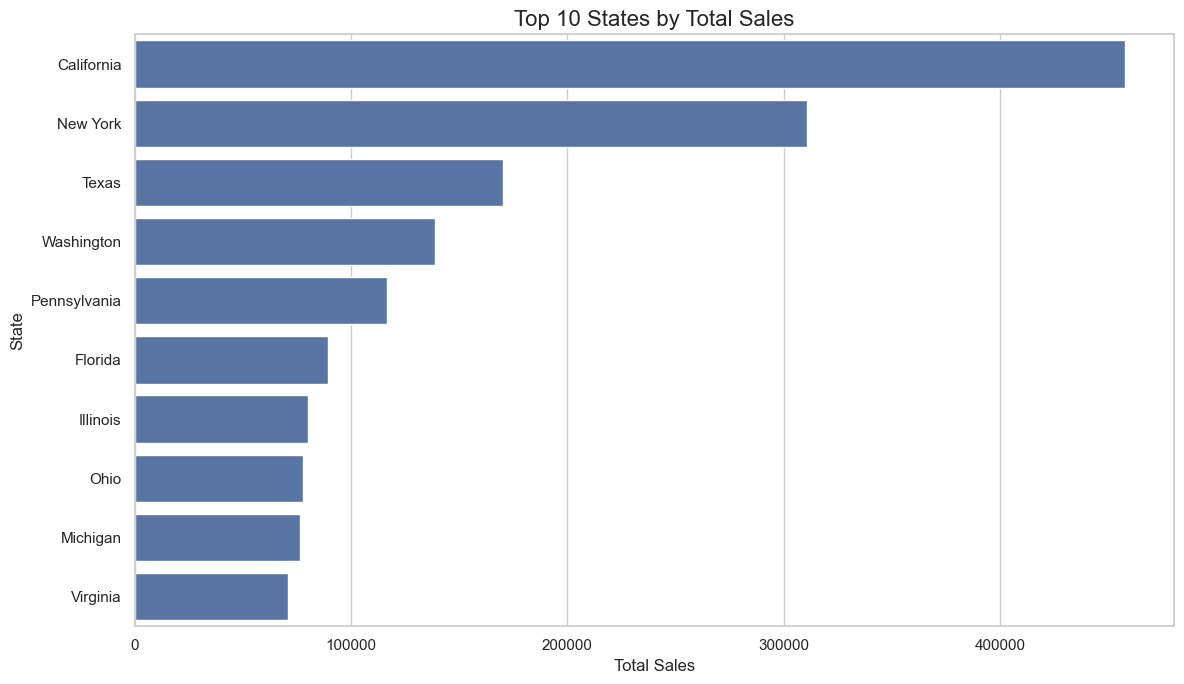

In [48]:

# 10. Top 10 states by sales
plt.figure(figsize=(12, 7))
sns.barplot(
    data=state_sales,
    x="Sales",
    y="State"
)
plt.title("Top 10 States by Total Sales", fontsize=16)
plt.xlabel("Total Sales")
plt.ylabel("State")
plt.tight_layout()
plt.savefig(charts_dir / "top_10_states.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()


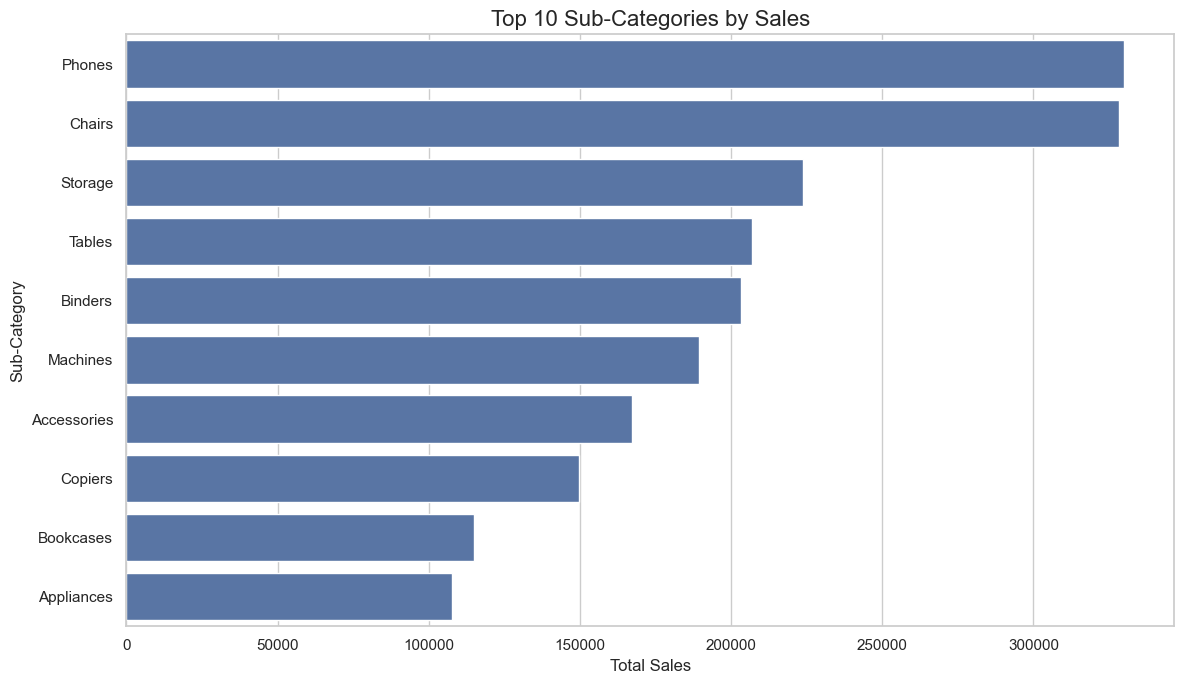

In [49]:
# 11. Top 10 sub-categories by sales
top_subcategories = subcategory_analysis.head(10)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_subcategories,
    x="Sales",
    y="Sub-Category"
)
plt.title("Top 10 Sub-Categories by Sales", fontsize=16)
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig(charts_dir / "top_10_subcategories.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

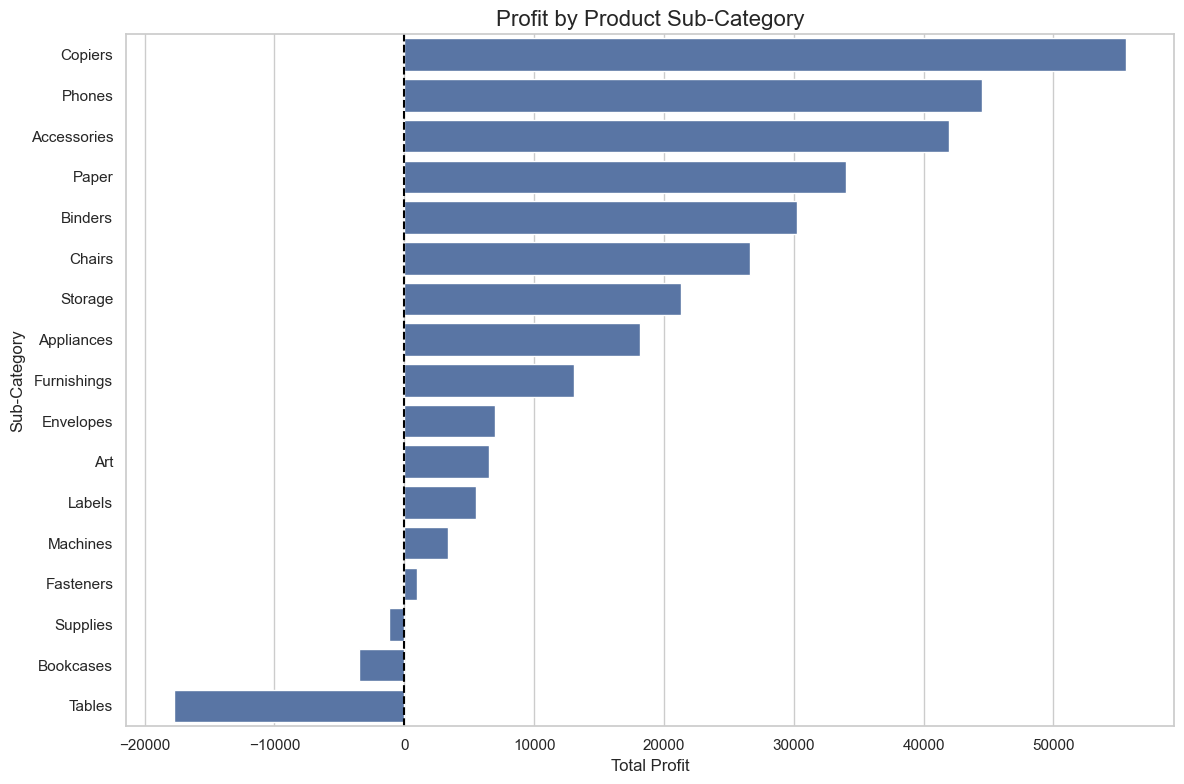

In [50]:

# 12. Profit by all sub-categories
plt.figure(figsize=(12, 8))
sns.barplot(
    data=profit_analysis,
    x="Profit",
    y="Sub-Category"
)
plt.axvline(x=0, linestyle="--", color="black")
plt.title("Profit by Product Sub-Category", fontsize=16)
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig(charts_dir / "subcategory_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()
 

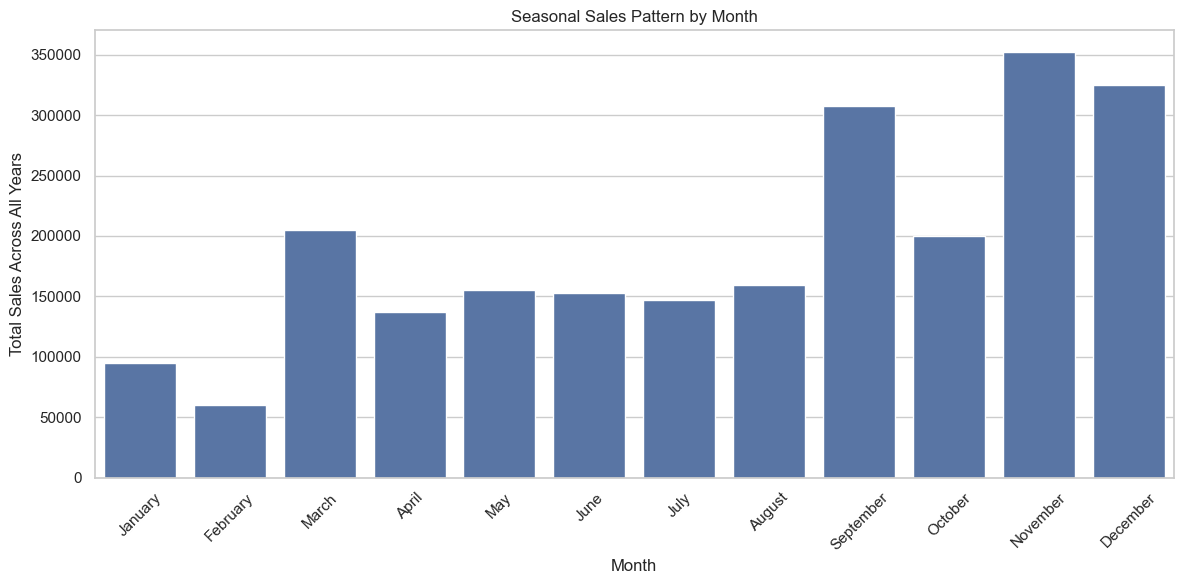

In [52]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=seasonal_sales,
    x="MonthName",
    y="Sales"
)

plt.title("Seasonal Sales Pattern by Month")
plt.xlabel("Month")
plt.ylabel("Total Sales Across All Years")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_dir / "seasonal_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

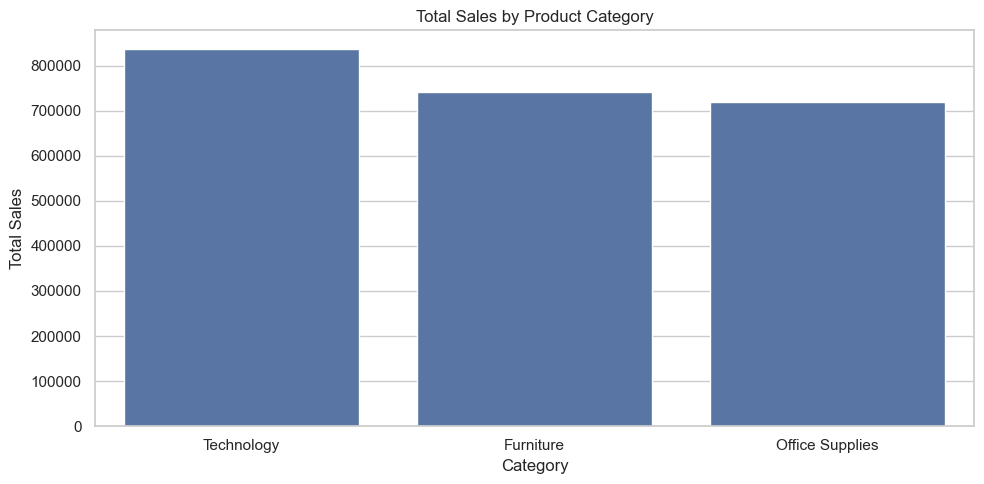

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    charts_dir / "category_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [54]:
saved_charts=list(charts_dir.glob("*.png"))
print('======chart export summrary=====')
print("charts folder:",charts_dir.resolve())
print("Total charts saved :",len(saved_charts))
for chart in saved_charts:
    print(f"{chart.name}-{chart.stat().st_size:,}bytes")
print("chart export process completed")    


======chart export summrary=====
charts folder: C:\Users\Akshaya\Downloads\CodeNova_Task1_Sales_Analysis\CodeNova_Task1_Sales_Analysis\notebooks\charts
Total charts saved : 12
category_profit.png-87,138bytes
category_sales.png-90,686bytes
monthly_sales_trend.png-310,134bytes
quarterly_sales_trend.png-214,553bytes
regional_profit.png-72,689bytes
regional_sales.png-79,180bytes
seasonal_sales.png-164,740bytes
segment_profit.png-87,473bytes
segment_sales.png-83,030bytes
subcategory_profit.png-171,187bytes
top_10_states.png-114,152bytes
top_10_subcategories.png-134,207bytes
chart export process completed


In [55]:
from pathlib import Path
outout_dir=Path("Output")
print("Output folder:",output_dir.resolve())
for file in output_dir.glob("*.csv"):
       print(f"✅ {file.name} - {file.stat().st_size:,} bytes")

Output folder: C:\Users\Akshaya\Downloads\CodeNova_Task1_Sales_Analysis\CodeNova_Task1_Sales_Analysis\notebooks\outputs
✅ category_analysis.csv - 157 bytes
✅ monthly_sales.csv - 969 bytes
✅ quarterly_sales.csv - 323 bytes
✅ region_analysis.csv - 171 bytes
✅ seasonal_sales.csv - 287 bytes
✅ segment_analysis.csv - 152 bytes
✅ subcategory_profit_analysis.csv - 658 bytes
✅ top_10_states.csv - 354 bytes
